In [7]:
"Import libraries and load the dataset"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("djia4_regression_data.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df["Ticker"].value_counts())

         Date   Open   High    Low  Close     Volume Ticker
0  04-01-2006  10.73  10.85  10.64  10.71  155225609   AAPL
1  05-01-2006  10.69  10.70  10.54  10.63  112396081   AAPL
2  06-01-2006  10.75  10.96  10.65  10.90  176139334   AAPL
3  09-01-2006  10.96  11.03  10.82  10.86  168861224   AAPL
4  10-01-2006  10.89  11.70  10.83  11.55  570088246   AAPL
(12071, 7)
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
Ticker    0
dtype: int64
Ticker
BA      3018
JPM     3018
KO      3018
AAPL    3017
Name: count, dtype: int64


In [8]:
"Preprocessing"
# Select numerical features only
features = ["Open", "High", "Low", "Close", "Volume"]
X = df[features].copy()

# Reduce skewness in trading volume
X["Volume"] = np.log1p(X["Volume"])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (12071, 5)


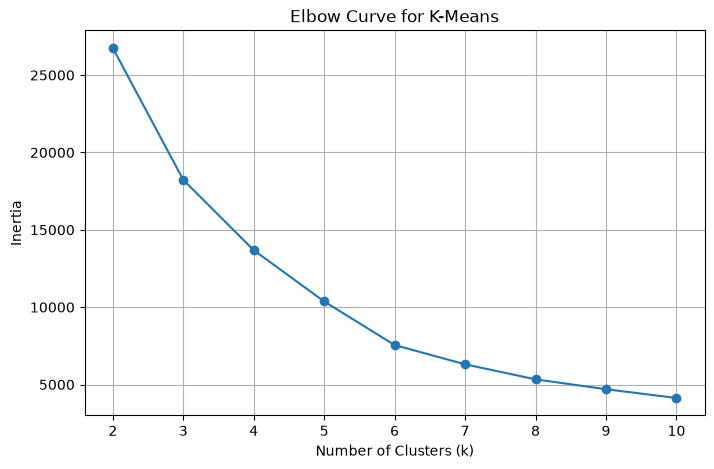

In [9]:
"K-Mean clustering - Elbow method"
inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Curve for K-Means")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [10]:
"Fit K-Means and calculate mandatory metrics"
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Silhouette Score:",
      silhouette_score(X_scaled, kmeans_labels))

print("K-Means Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, kmeans_labels))

print("K-Means Calinski-Harabasz Index:",
      calinski_harabasz_score(X_scaled, kmeans_labels))

K-Means Silhouette Score: 0.4389802399998287
K-Means Davies-Bouldin Index: 0.799721648879946
K-Means Calinski-Harabasz Index: 13717.203773683003


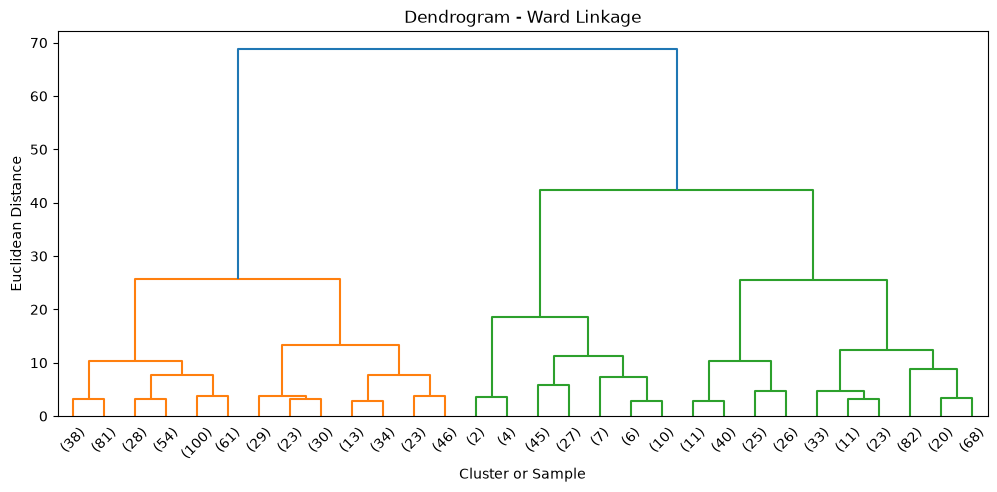

In [11]:
"Agglomerative hierarchical clustering"
from sklearn.model_selection import train_test_split

# Use a sample for hierarchical clustering
rng = np.random.RandomState(42)
sample_idx = rng.choice(
    len(X_scaled),
    size=1000,
    replace=False
)

X_agg = X_scaled[sample_idx]

# Dendrogram using Ward linkage
Z = linkage(X_agg, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Dendrogram - Ward Linkage")
plt.xlabel("Cluster or Sample")
plt.ylabel("Euclidean Distance")
plt.show()

In [12]:
"Compare linkage strategies"
linkage_methods = ["ward", "complete", "average"]
agg_results = {}

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=4,
        linkage=method
    )

    labels = model.fit_predict(X_agg)
    agg_results[method] = labels

    print("\nLinkage:", method)
    print("Silhouette Score:",
          silhouette_score(X_agg, labels))
    print("Davies-Bouldin Index:",
          davies_bouldin_score(X_agg, labels))
    print("Calinski-Harabasz Index:",
          calinski_harabasz_score(X_agg, labels))


Linkage: ward
Silhouette Score: 0.3801609490382873
Davies-Bouldin Index: 0.8188299642747435
Calinski-Harabasz Index: 1027.5665828102433

Linkage: complete
Silhouette Score: 0.349511882855992
Davies-Bouldin Index: 0.8190158603285675
Calinski-Harabasz Index: 888.1797836391477

Linkage: average
Silhouette Score: 0.45073755648688524
Davies-Bouldin Index: 0.7577752639449928
Calinski-Harabasz Index: 824.3054806783235


Explained variance ratio: [0.85029761 0.14952842]
Total variance explained: 0.9998260222016231


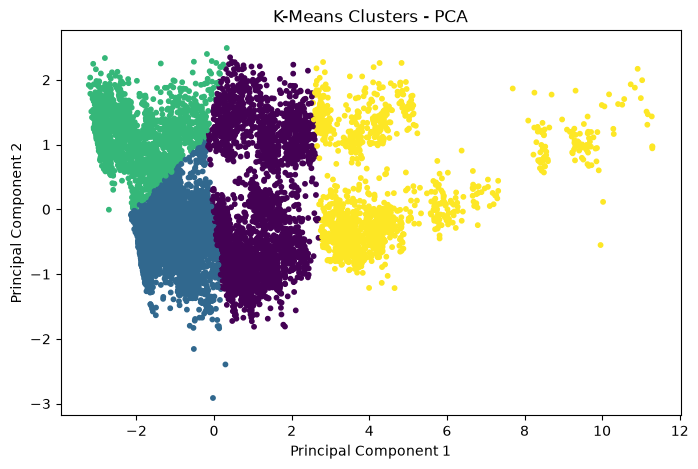

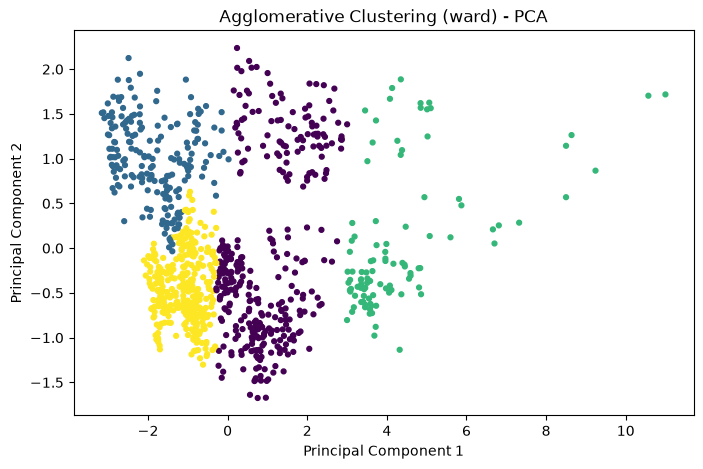

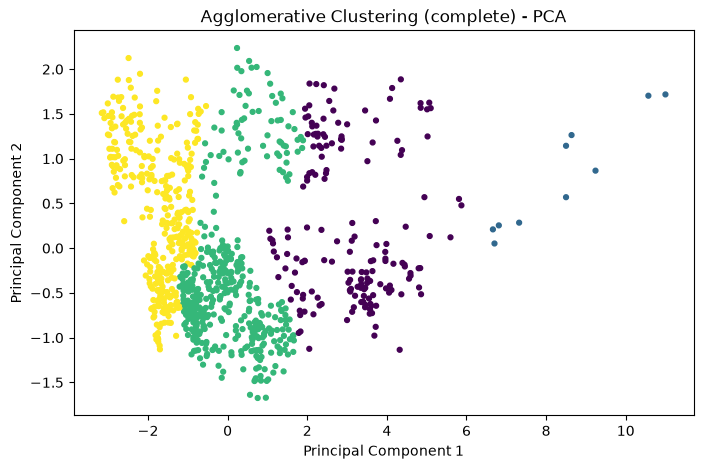

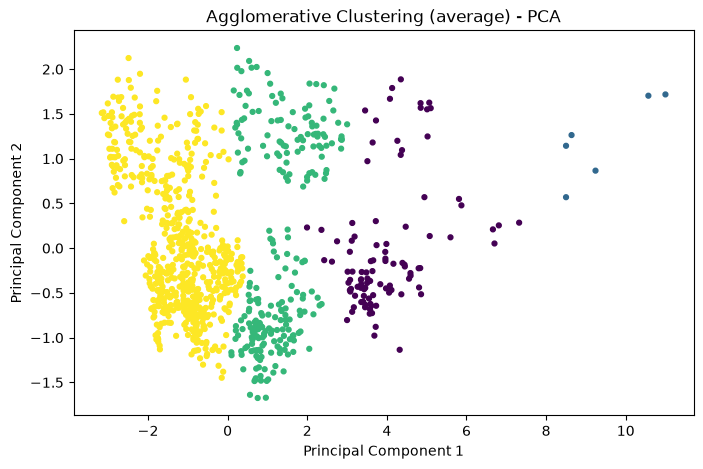

In [13]:
"PCA visualization"
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:",
      pca.explained_variance_ratio_.sum())

# K-Means visualization
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=10
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters - PCA")
plt.show()

# Agglomerative visualization using the same sample
X_agg_pca = X_pca[sample_idx]

for method in linkage_methods:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        X_agg_pca[:, 0],
        X_agg_pca[:, 1],
        c=agg_results[method],
        cmap="viridis",
        s=12
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title(f"Agglomerative Clustering ({method}) - PCA")
    plt.show()

In [14]:
"Compare all algorithms in one table"
results = []

# K-Means metrics
results.append({
    "Algorithm": "K-Means",
    "Silhouette Score": silhouette_score(X_scaled, kmeans_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, kmeans_labels)
})

# Agglomerative metrics
for method, labels in agg_results.items():
    results.append({
        "Algorithm": f"Agglomerative ({method})",
        "Silhouette Score": silhouette_score(X_agg, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_agg, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_agg, labels)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

               Algorithm  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
                 K-Means            0.4390                0.7997               13717.2038
    Agglomerative (ward)            0.3802                0.8188                1027.5666
Agglomerative (complete)            0.3495                0.8190                 888.1798
 Agglomerative (average)            0.4507                0.7578                 824.3055
